# OARL-NET inference example

Run organelle segmentation and perturbation classification on one tomogram.
Install `requirements-notebooks.txt`, download the classification dataset, and
place both model weights in `checkpoints/` as described in the repository README.
Only the ODT images are read. A GPU is optional.

In [1]:
%matplotlib inline

from pathlib import Path
import csv
import sys

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import numpy as np
import torch
from torch.utils.data import DataLoader

ROOT = Path(".") if Path("oarl_net").is_dir() else Path("..")
sys.path.insert(0, str(ROOT.resolve()))

from oarl_net import Config, ODTDataset, create_model, load_tomograms
from oarl_net.checkpoint import load_weights
from oarl_net.cls_trainer import predict
from predict_segmentation import predict_tomogram

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cpu":
    torch.set_num_threads(min(4, torch.get_num_threads()))
print(f"Device: {device}")

Device: cpu


## Load one tomogram

Set `DATA_DIR` to the extracted classification dataset. The first tomogram in
the classification test split is selected by default. Set `TOMOGRAM_ID` to
another ID in that split to try a different example.

Loading tomograms:   0%|          | 0/1 [00:00<?, ?it/s]

Loading tomograms: 100%|██████████| 1/1 [00:00<00:00,  2.30it/s]

Loading tomograms: 100%|██████████| 1/1 [00:00<00:00,  2.30it/s]

Tomogram: odt_0610 (Ctrl)
Selected input: (741, 741, 7) (height, width, z)


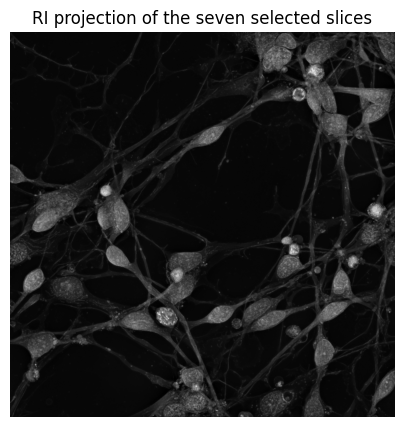

In [2]:
DATA_DIR = ROOT / ".." / "classification_dataset"
TOMOGRAM_ID = None

cfg = Config()
tomograms = load_tomograms(
    ROOT / "metadata" / "tomograms.csv", DATA_DIR,
    task="classification", split="test",
)
if TOMOGRAM_ID is None:
    tomogram = tomograms[0]
else:
    tomogram = next((t for t in tomograms if t.id == TOMOGRAM_ID), None)
    if tomogram is None:
        raise ValueError(f"{TOMOGRAM_ID} is not in the classification test split")

dataset = ODTDataset(
    [tomogram], cfg.data, augment=False, use_subimages=True,
    classification_only=True, in_memory=True,
)
image = dataset.images[0]
projection = image.max(axis=2)

print(f"Tomogram: {tomogram.id} ({tomogram.chemical})")
print(f"Selected input: {image.shape} (height, width, z)")
fig, ax = plt.subplots(figsize=(5, 5))
ax.imshow(projection, cmap="gray", vmin=0, vmax=1)
ax.set_title("RI projection of the seven selected slices")
ax.axis("off")
plt.show()

## Organelle segmentation

Predict the full field of view using overlapping tiles. `TILE_BATCH_SIZE`
controls memory use. The maps contain probabilities in nucleus, lysosome,
mitochondria order; `segmentation_probabilities > 0.5` gives binary masks.

loaded 417 tensors from ../checkpoints/segmentation.pth (epoch 244)


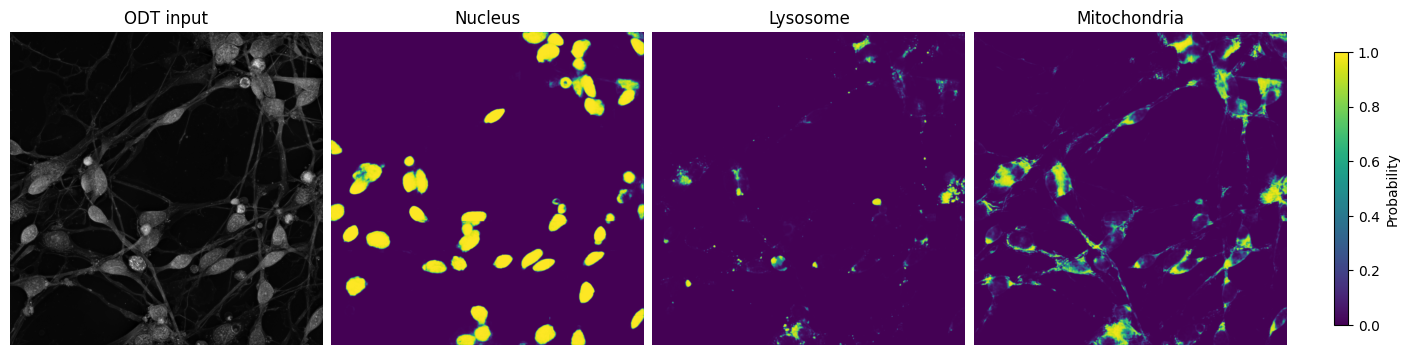

In [3]:
TILE_BATCH_SIZE = 1

segmentation_model = create_model(cfg.model)
load_weights(segmentation_model, ROOT / "checkpoints" / "segmentation.pth")
segmentation_model = segmentation_model.to(device).eval()
segmentation_probabilities = predict_tomogram(
    segmentation_model, image, cfg.data.crop_size, device,
    batch_size=TILE_BATCH_SIZE,
)

fig, axes = plt.subplots(1, 4, figsize=(14, 3.6), layout="constrained")
axes[0].imshow(projection, cmap="gray", vmin=0, vmax=1)
axes[0].set_title("ODT input")
for ax, organelle, probability in zip(
    axes[1:], cfg.data.organelles, segmentation_probabilities
):
    panel = ax.imshow(probability, cmap="viridis", vmin=0, vmax=1)
    ax.set_title(organelle.capitalize())
for ax in axes:
    ax.axis("off")
fig.colorbar(panel, ax=list(axes[1:]), label="Probability", shrink=0.8)
plt.show()
del segmentation_model

## Perturbation classification

The classifier evaluates nine fixed crops. A tomogram is classified as perturbed
when at least five crops have probability above 0.5. The mean crop probability
is also reported as a continuous score.

loaded 395 tensors from ../checkpoints/classification.pth (epoch 109)


Reference: Control (Ctrl)
Prediction: Control
Positive crops: 1/9
Mean crop probability: 0.1285


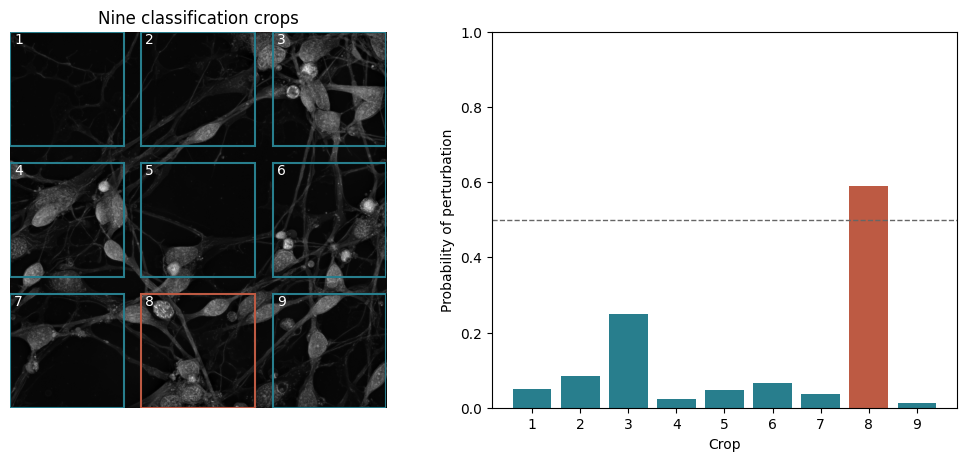

In [4]:
cfg.model.classification_mode = True
cfg.model.enable_heatmap_head = False
classification_model = create_model(cfg.model)
load_weights(classification_model, ROOT / "checkpoints" / "classification.pth")
classification_model = classification_model.to(device).eval()

loader = DataLoader(dataset, batch_size=3, shuffle=False, num_workers=0)
probabilities_by_id, _ = predict(classification_model, loader, device)
crop_probabilities = np.array(probabilities_by_id[tomogram.id])
positive_crops = int((crop_probabilities > 0.5).sum())
prediction = int(positive_crops >= 5)
mean_probability = float(crop_probabilities.mean())
class_names = {0: "Control", 1: "ETC-perturbed"}

print(f"Reference: {class_names[tomogram.label]} ({tomogram.chemical})")
print(f"Prediction: {class_names[prediction]}")
print(f"Positive crops: {positive_crops}/9")
print(f"Mean crop probability: {mean_probability:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), layout="constrained")
axes[0].imshow(projection, cmap="gray", vmin=0, vmax=1)
colors = ["#bd5a43" if p > 0.5 else "#287e8d" for p in crop_probabilities]
for number, ((y, x), color) in enumerate(zip(dataset.subimage_positions, colors), 1):
    axes[0].add_patch(Rectangle(
        (x, y), cfg.data.crop_size, cfg.data.crop_size,
        fill=False, edgecolor=color, linewidth=1.5,
    ))
    axes[0].text(x + 8, y + 22, str(number), color="white", fontsize=10)
axes[0].set_title("Nine classification crops")
axes[0].axis("off")
axes[1].bar(np.arange(1, 10), crop_probabilities, color=colors)
axes[1].axhline(0.5, color="0.4", linestyle="--", linewidth=1)
axes[1].set(xticks=np.arange(1, 10), ylim=(0, 1), xlabel="Crop",
            ylabel="Probability of perturbation")
plt.show()
del classification_model

## Save predictions

Save the probability maps and a classification CSV under `predictions/`.
The NPZ stores the three maps as float16; the CSV includes all nine crop scores.

In [5]:
output_dir = ROOT / "predictions" / tomogram.id
output_dir.mkdir(parents=True, exist_ok=True)
np.savez_compressed(
    output_dir / "segmentation.npz",
    probabilities=segmentation_probabilities.astype(np.float16),
    organelles=np.array(cfg.data.organelles), well=tomogram.well,
)
row = {
    "tomogram": tomogram.id, "chemical": tomogram.chemical,
    "plate": tomogram.plate, "well": tomogram.well, "session": tomogram.session,
    "label": tomogram.label, "n_subimages": len(crop_probabilities),
    "tomogram_probability": f"{mean_probability:.6f}", "prediction": prediction,
    "subimage_probabilities": ";".join(f"{p:.6f}" for p in crop_probabilities),
}
with (output_dir / "classification.csv").open("w", newline="") as stream:
    writer = csv.DictWriter(stream, fieldnames=row.keys())
    writer.writeheader()
    writer.writerow(row)
print(f"Saved predictions to {output_dir}")

Saved predictions to ../predictions/odt_0610
